[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/attention-explained/blob/main/notebooks/10_masked_attention.ipynb)

# 10 · Masked (Causal) Attention

*Attention, Explained · Hamza Hentabli, Ph.D. · ~25 min*

Models like GPT write text one token at a time, and must never see the future while learning to predict it. **Causal masking** enforces that with one triangular matrix. In this notebook we build the mask, visualise its effect on the softmax, prove nothing leaks from the future, and show by experiment what goes wrong without it.

**Learning objectives.** By the end of this notebook you will be able to:

- explain **autoregressive** generation and why training needs a **causal mask**
- apply the mask **before** the softmax and visualise the triangular pattern
- prove numerically that future tokens cannot affect past outputs
- show by training that an unmasked model **cheats** and fails at generation
- explain the **KV cache**

In [1]:
# Setup: on Google Colab this installs anything missing and clones the repo so the
# shared `attn_utils` helper is available. Running locally, install requirements.txt
# once and this cell just locates the files. No notebook needs the network after this.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
OFFLINE = os.environ.get("ATTN_OFFLINE", "0") == "1"   # CI sets this; everything is computed locally
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "numpy", "torch", "matplotlib", "scikit-learn"], check=True)
    if not os.path.isdir("attention-explained"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/attention-explained.git"], check=True)
    ROOT = "attention-explained"
else:
    ROOT = ".." if os.path.exists("../attn_utils.py") else "."
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import numpy as np
import matplotlib.pyplot as plt
import attn_utils as au

au.set_docs_dir(os.path.join(ROOT, "docs"))
au.set_seed(0)
np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print("Colab:", IN_COLAB, "| offline:", OFFLINE, "| numpy", np.__version__)


Colab: False | offline: True | numpy 2.4.6


## 1. Generating text one token at a time

A **decoder** language model (GPT-style) writes text **autoregressively**: predict the next token, append it, predict again.

> *the* → *cat* → *sat* → *on* → …

During **training**, though, we feed the whole sentence at once and ask for a prediction at **every** position in parallel (that is what makes Transformers fast to train). Position 3 must predict token 4 — but with ordinary self-attention, position 3 can simply *look at* token 4 and copy it. The model would learn to cheat.

The fix is a **causal mask**: position $i$ may attend only to positions $\le i$. Everything in the future is hidden.

## 2. The mask, step by step

In [2]:
tokens = ["<s>", "the", "cat", "sat", "on", "the", "mat"]
n = len(tokens)
rng = np.random.default_rng(3)
X = rng.normal(size=(n, 8))
WQ, WK = rng.normal(scale=8 ** -0.5, size=(8, 8)), rng.normal(scale=8 ** -0.5, size=(8, 8))
scores = (X @ WQ) @ (X @ WK).T / np.sqrt(8)

mask = au.causal_mask(n)           # True above the diagonal = "future, not allowed"
print(mask.astype(int))
masked_scores = np.where(mask, -np.inf, scores)
weights = au.softmax(masked_scores)
print("\nfirst rows of the causal attention weights:")
print(weights[:3].round(3))

[[0 1 1 1 1 1 1]
 [0 0 1 1 1 1 1]
 [0 0 0 1 1 1 1]
 [0 0 0 0 1 1 1]
 [0 0 0 0 0 1 1]
 [0 0 0 0 0 0 1]
 [0 0 0 0 0 0 0]]

first rows of the causal attention weights:
[[1.    0.    0.    0.    0.    0.    0.   ]
 [0.826 0.174 0.    0.    0.    0.    0.   ]
 [0.14  0.487 0.373 0.    0.    0.    0.   ]]


Setting a score to $-\infty$ makes $e^{-\infty} = 0$, so the softmax gives the future **exactly zero** weight while the allowed positions still sum to 1. The first token can only look at itself (weight 1.0).

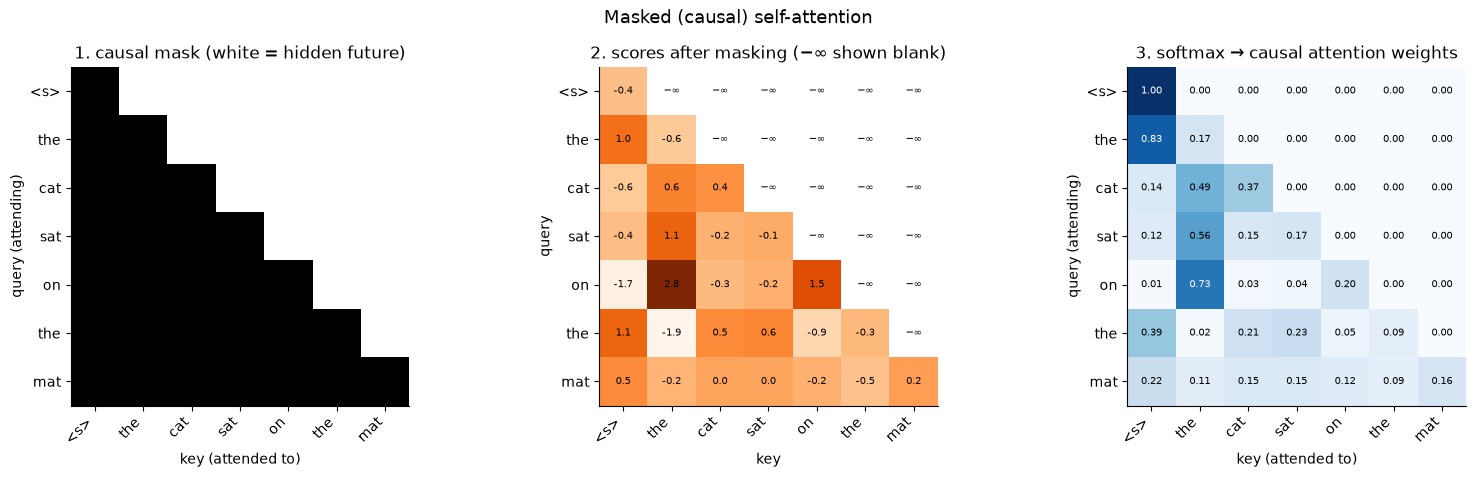

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
au.plot_attention(~mask * 1.0, tokens, tokens, ax=axes[0], annotate=False, cmap="Greys", vmax=1,
                  title="1. causal mask (white = hidden future)")
show = np.where(mask, np.nan, scores)
im = axes[1].imshow(show, cmap="Oranges"); axes[1].set_title("2. scores after masking (−∞ shown blank)")
axes[1].set_xticks(range(n)); axes[1].set_xticklabels(tokens, rotation=45, ha="right")
axes[1].set_yticks(range(n)); axes[1].set_yticklabels(tokens); axes[1].set_xlabel("key"); axes[1].set_ylabel("query")
for r in range(n):
    for c in range(n):
        axes[1].text(c, r, "−∞" if mask[r, c] else f"{scores[r, c]:.1f}", ha="center", va="center", fontsize=7)
au.plot_attention(weights, tokens, tokens, ax=axes[2], title="3. softmax → causal attention weights")
fig.suptitle("Masked (causal) self-attention", fontsize=13)
plt.tight_layout()
au.save_fig(fig, "10_causal_mask.png")
plt.show()

### Mask *before* the softmax, not after

A tempting shortcut is to compute a normal softmax and then zero the future. That breaks the probability distribution: the remaining weights no longer sum to 1, and the future still influenced them through the denominator.

In [4]:
wrong = au.softmax(scores) * ~mask
print("row sums, masked BEFORE softmax:", weights.sum(1).round(3))
print("row sums, zeroed AFTER softmax :", wrong.sum(1).round(3))
renorm = wrong / wrong.sum(1, keepdims=True)
print("renormalising the wrong version recovers the right one:", np.allclose(renorm, weights))

row sums, masked BEFORE softmax: [1. 1. 1. 1. 1. 1. 1.]
row sums, zeroed AFTER softmax : [0.032 0.544 0.377 0.543 0.774 0.968 1.   ]
renormalising the wrong version recovers the right one: True


(Renormalising happens to recover the right answer, but setting $-\infty$ before the softmax is simpler, numerically safer, and what every library does.)

## 3. Proof that nothing leaks from the future

Change the **last** token and recompute. With the mask, the outputs at all earlier positions must be **bit-for-bit identical**; without it, every position changes.

In [5]:
WV = rng.normal(scale=8 ** -0.5, size=(8, 8))
def self_attn(X, causal):
    return au.scaled_dot_product_attention(X @ WQ, X @ WK, X @ WV, mask=au.causal_mask(len(X)) if causal else None)[0]

X_changed = X.copy(); X_changed[-1] = rng.normal(size=8)        # a different final word
for causal in (True, False):
    diff = np.abs(self_attn(X, causal) - self_attn(X_changed, causal)).max(1)
    print(f"causal={causal!s:5s}  change at each position:", diff.round(4))

causal=True   change at each position: [0.    0.    0.    0.    0.    0.    0.519]
causal=False  change at each position: [0.203 0.643 0.127 0.249 0.1   0.277 0.519]


## 4. What happens if you forget the mask? A training experiment

Toy language: every sequence counts upward modulo 12 from a random start — `7 8 9 10 11 0 1 2 …`. Knowing the rule, the next token is perfectly predictable from the current one.

We train two identical one-layer models on next-token prediction, **with** and **without** the causal mask, then ask each to **generate** 10 tokens from a 1-token prompt.

In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F
torch.set_num_threads(4)

VOCAB, L, D = 12, 16, 32

def counting_batch(B):
    start = torch.randint(0, VOCAB, (B, 1))
    return (start + torch.arange(L + 1)) % VOCAB        # inputs = seq[:, :-1], targets = seq[:, 1:]

class TinyDecoder(nn.Module):
    def __init__(self, causal):
        super().__init__()
        self.causal = causal
        self.emb = nn.Embedding(VOCAB, D)
        self.pos = nn.Parameter(torch.randn(L, D) * 0.3)
        self.attn = nn.MultiheadAttention(D, 2, batch_first=True)
        self.out = nn.Linear(D, VOCAB)
    def forward(self, x):
        T = x.shape[1]
        h = self.emb(x) + self.pos[:T]
        m = torch.triu(torch.ones(T, T, dtype=torch.bool), 1) if self.causal else None
        a, _ = self.attn(h, h, h, attn_mask=m)
        return self.out(h + a)

def train(causal, steps=400):
    au.set_seed(0)
    model = TinyDecoder(causal)
    opt = torch.optim.Adam(model.parameters(), lr=3e-3)
    for _ in range(steps):
        seq = counting_batch(64)
        loss = F.cross_entropy(model(seq[:, :-1]).reshape(-1, VOCAB), seq[:, 1:].reshape(-1))
        opt.zero_grad(); loss.backward(); opt.step()
    return model, loss.item()

@torch.no_grad()
def generate(model, prompt, n_new=10):
    seq = list(prompt)
    for _ in range(n_new):
        logits = model(torch.tensor([seq]))
        seq.append(int(logits[0, -1].argmax()))
    return seq

for causal in (True, False):
    model, final_loss = train(causal)
    gen_ok = []
    for start in range(VOCAB):
        out = generate(model, [start])
        gen_ok.append(np.mean([out[i + 1] == (out[0] + i + 1) % VOCAB for i in range(10)]))
    print(f"causal mask = {causal!s:5s} | final TRAINING loss {final_loss:.4f} | "
          f"generation accuracy {np.mean(gen_ok):.3f} | from prompt [3]: {generate(model, [3])}")

causal mask = True  | final TRAINING loss 0.0003 | generation accuracy 1.000 | from prompt [3]: [3, 4, 5, 6, 7, 8, 9, 10, 11, 0, 1]


causal mask = False | final TRAINING loss 0.0002 | generation accuracy 0.167 | from prompt [3]: [3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3]


The model trained **without** the mask reaches a training loss as good as (or better than) the honest one — it learned to read the answer from the next position. But at generation time there *is* no next position, so it cannot continue the sequence. The masked model learned the actual rule and generates correctly. **The causal mask is what makes training match generation.**

## 5. Bonus: the KV cache

Because position $i$ never looks forward, the keys and values of earlier positions never change as new tokens are added. During generation a model can **cache** them and compute attention only for the newest query. This *KV cache* is why chatbots can stream long answers efficiently. Check that the incremental computation matches the full masked one:

In [7]:
Q_all, K_all, V_all = X @ WQ, X @ WK, X @ WV
full = au.scaled_dot_product_attention(Q_all, K_all, V_all, mask=au.causal_mask(n))[0]

K_cache, V_cache, incremental = [], [], []
for t in range(n):                       # tokens arrive one at a time
    K_cache.append(K_all[t]); V_cache.append(V_all[t])
    z, _ = au.scaled_dot_product_attention(Q_all[t:t + 1], np.array(K_cache), np.array(V_cache))
    incremental.append(z[0])
print("incremental (KV cache) == full causal attention:", np.allclose(np.array(incremental), full))

incremental (KV cache) == full causal attention: True


## Key takeaways

- **Causal (masked) attention** lets position $i$ attend only to positions $\le i$, via a triangular mask of $-\infty$ **before** the softmax.
- It makes parallel training **equivalent** to left-to-right generation — no peeking.
- Forgetting it produces a model that looks great in training and **fails at generation** (measured above).
- The mask also enables the **KV cache** for fast generation.
- Encoders (BERT) use **no** mask; decoders (GPT) use the causal mask — the subject of Notebook 12.

### ✏️ Exercise 1

Build the causal mask for 5 tokens and count how many (query, key) pairs are allowed. What is the formula for n tokens?

<details>
<summary><b>Show solution</b></summary>

```python
m5 = au.causal_mask(5)
print((~m5).sum(), "= n(n+1)/2 =", 5 * 6 // 2)
```



</details>

### ✏️ Exercise 2

A *prefix-LM* mask lets the first k tokens see each other fully, while the rest stays causal. Build it for n=7, k=3 and plot it.

<details>
<summary><b>Show solution</b></summary>

```python
k = 3
m = au.causal_mask(7)
m[:k, :k] = False
au.plot_attention(~m * 1.0, tokens, tokens, cmap="Greys", annotate=False); plt.show()
```



</details>

### ✏️ Exercise 3

Generate 15 tokens from the prompt `[0, 1]` with the causal model. (Note: our positional table only covers 16 positions.)

<details>
<summary><b>Show solution</b></summary>

```python
causal_model, _ = train(True)
print(generate(causal_model, [0, 1], n_new=14))
```



</details>